In [8]:
# ==========================================
# REVISI DOSEN
# LOAD MODEL + TEST DATA
# ==========================================

import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import load_model

BASE_DIR = r"C:\Users\TUF\CodeJurnalRevisi"

IMG_SIZE = (224,224)

print("Library siap.")

Library siap.


In [9]:
# ==========================================
# LOAD BEST MODEL
# ==========================================

from tensorflow.keras.models import load_model
import os

MODEL_PATH = os.path.join(
    BASE_DIR,
    "best_model_balanced.h5"
)

model = load_model(MODEL_PATH)

print("Model berhasil dimuat")
print("Input Shape :", model.input_shape)
print("Output Shape:", model.output_shape)

Model berhasil dimuat
Input Shape : (None, 224, 224, 3)
Output Shape: (None, 20)


In [10]:
# ==========================================
# LOAD TEST DATA
# ==========================================

import pandas as pd
import os

TEST_CSV = os.path.join(
    BASE_DIR,
    "test_data.csv"
)

test_df = pd.read_csv(TEST_CSV)

print("Jumlah data test :", len(test_df))
print()

print(test_df.head())

Jumlah data test : 280

        filename                                           filepath  \
0  008703357.jpg  D:\Semester 6\METOPEN\Dataset\images\008703357...   
1  026614995.jpg  D:\Semester 6\METOPEN\Dataset\images\026614995...   
2  041844679.jpg  D:\Semester 6\METOPEN\Dataset\images\041844679...   
3  092076481.jpg  D:\Semester 6\METOPEN\Dataset\images\092076481...   
4  000845150.jpg  D:\Semester 6\METOPEN\Dataset\images\000845150...   

                        label  
0            skiing, downhill  
1  bicycling, racing and road  
2               aerobic, step  
3                        golf  
4     ballet, modern, or jazz  


Data Ke       : 0
Index Prediksi: 8
Label Asli    : skiing, downhill


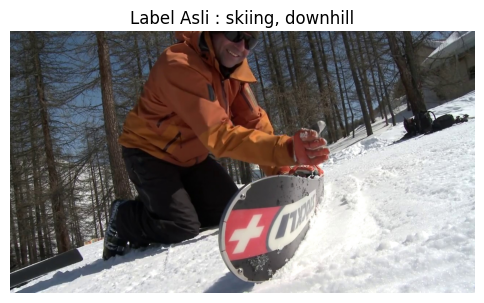

In [7]:
# ==========================================
# CONTOH 1 HASIL PREDIKSI
# ==========================================

index_data = 0

sample = test_df.iloc[index_data]

img_path = sample["filepath"]
true_label = sample["label"]

# baca gambar
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# resize untuk model
img_resized = cv2.resize(img_rgb, IMG_SIZE)

# preprocess inceptionv3
img_input = tf.keras.applications.inception_v3.preprocess_input(
    np.expand_dims(img_resized, axis=0)
)

# prediksi
pred = model.predict(img_input, verbose=0)

pred_class = np.argmax(pred)

print("Data Ke       :", index_data)
print("Index Prediksi:", pred_class)
print("Label Asli    :", true_label)

plt.figure(figsize=(6,6))
plt.imshow(img_rgb)
plt.title(f"Label Asli : {true_label}")
plt.axis("off")
plt.show()

In [9]:
# ==========================================
# CARI 10 CONTOH PREDIKSI
# ==========================================

for i in range(10):

    sample = test_df.iloc[i]

    img_path = sample["filepath"]
    true_label = sample["label"]

    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img_resized = cv2.resize(img_rgb, IMG_SIZE)

    img_input = tf.keras.applications.inception_v3.preprocess_input(
        np.expand_dims(img_resized, axis=0)
    )

    pred = model.predict(img_input, verbose=0)

    pred_class = np.argmax(pred)
    pred_label = classes_list[pred_class]

    print(f"Data {i}")
    print("Asli     :", true_label)
    print("Prediksi :", pred_label)
    print("-"*50)

Data 0
Asli     : skiing, downhill
Prediksi : forestry
--------------------------------------------------
Data 1
Asli     : bicycling, racing and road
Prediksi : bicycling, racing and road
--------------------------------------------------
Data 2
Asli     : aerobic, step
Prediksi : aerobic, step
--------------------------------------------------
Data 3
Asli     : golf
Prediksi : golf
--------------------------------------------------
Data 4
Asli     : ballet, modern, or jazz
Prediksi : ballet, modern, or jazz
--------------------------------------------------
Data 5
Asli     : bicycling, mountain
Prediksi : bicycling, mountain
--------------------------------------------------
Data 6
Asli     : bicycling, mountain
Prediksi : bicycling, mountain
--------------------------------------------------
Data 7
Asli     : video exercise workouts, TV conditioning programs
Prediksi : video exercise workouts, TV conditioning programs
--------------------------------------------------
Data 8
Asli   

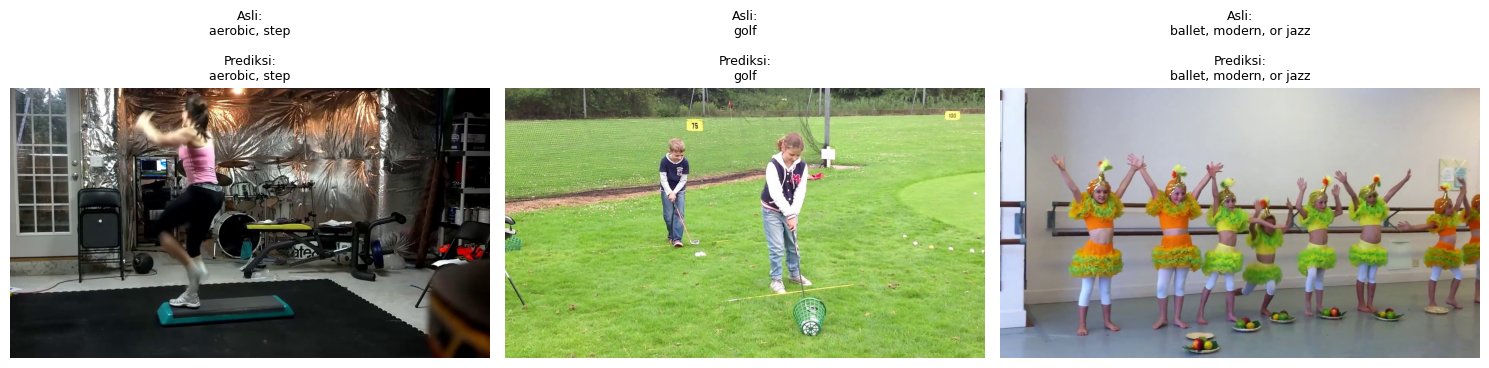

In [10]:
# ==========================================
# TAMPILKAN 3 HASIL PREDIKSI BENAR
# ==========================================

selected_index = [2, 3, 4]

plt.figure(figsize=(15,5))

for i, idx in enumerate(selected_index):

    sample = test_df.iloc[idx]

    img_path = sample["filepath"]
    true_label = sample["label"]

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img_resize = cv2.resize(img, IMG_SIZE)

    img_input = tf.keras.applications.inception_v3.preprocess_input(
        np.expand_dims(img_resize, axis=0)
    )

    pred = model.predict(img_input, verbose=0)

    pred_class = np.argmax(pred)
    pred_label = classes_list[pred_class]

    plt.subplot(1,3,i+1)
    plt.imshow(img)
    plt.title(
        f"Asli:\n{true_label}\n\nPrediksi:\n{pred_label}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

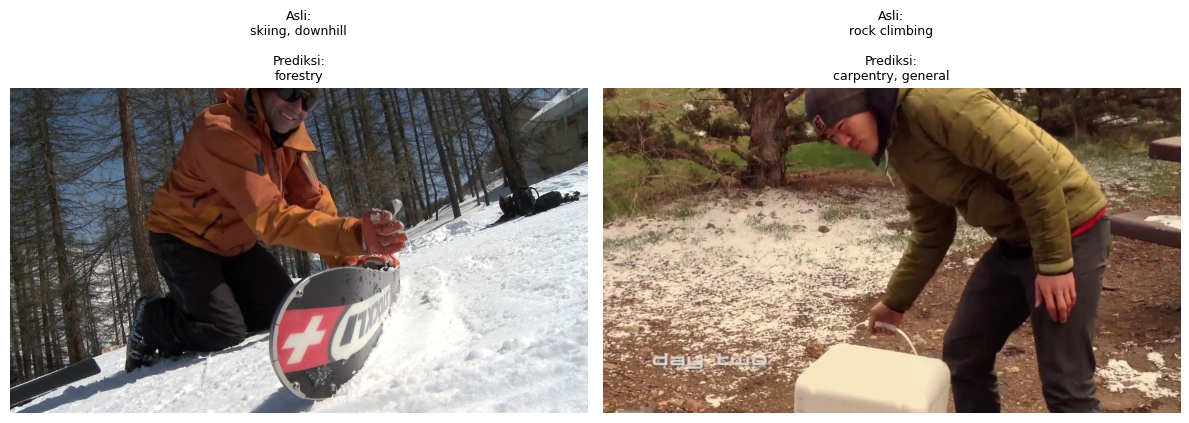

In [12]:
# ==========================================
# CONTOH HASIL KLASIFIKASI SALAH
# ==========================================

selected_index = [0, 8]

plt.figure(figsize=(12,5))

for i, idx in enumerate(selected_index):

    sample = test_df.iloc[idx]

    img_path = sample["filepath"]
    true_label = sample["label"]

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img_resize = cv2.resize(img, IMG_SIZE)

    img_input = tf.keras.applications.inception_v3.preprocess_input(
        np.expand_dims(img_resize, axis=0)
    )

    pred = model.predict(img_input, verbose=0)

    pred_class = np.argmax(pred)
    pred_label = classes_list[pred_class]

    plt.subplot(1,2,i+1)
    plt.imshow(img)
    plt.title(
        f"Asli:\n{true_label}\n\nPrediksi:\n{pred_label}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [30]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def predict_sample(idx):
    sample = test_df.iloc[idx]
    img_path = sample["filepath"]
    true_label = sample["label"]

    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resize = cv2.resize(img_rgb, IMG_SIZE)

    img_input = tf.keras.applications.inception_v3.preprocess_input(
        np.expand_dims(img_resize, axis=0)
    )

    pred = model.predict(img_input, verbose=0)
    pred_class = np.argmax(pred)
    pred_label = classes_list[pred_class]

    return img_rgb, true_label, pred_label

# cari 2 contoh benar dan 2 contoh salah
benar = []
salah = []

for idx in np.random.permutation(len(test_df)):
    img_rgb, true_label, pred_label = predict_sample(idx)

    if true_label == pred_label and len(benar) < 2:
        benar.append((img_rgb, true_label, pred_label))
    elif true_label != pred_label and len(salah) < 2:
        salah.append((img_rgb, true_label, pred_label))

    if len(benar) == 2 and len(salah) == 2:
        break

print("Jumlah benar:", len(benar))
print("Jumlah salah:", len(salah))

Jumlah benar: 2
Jumlah salah: 2


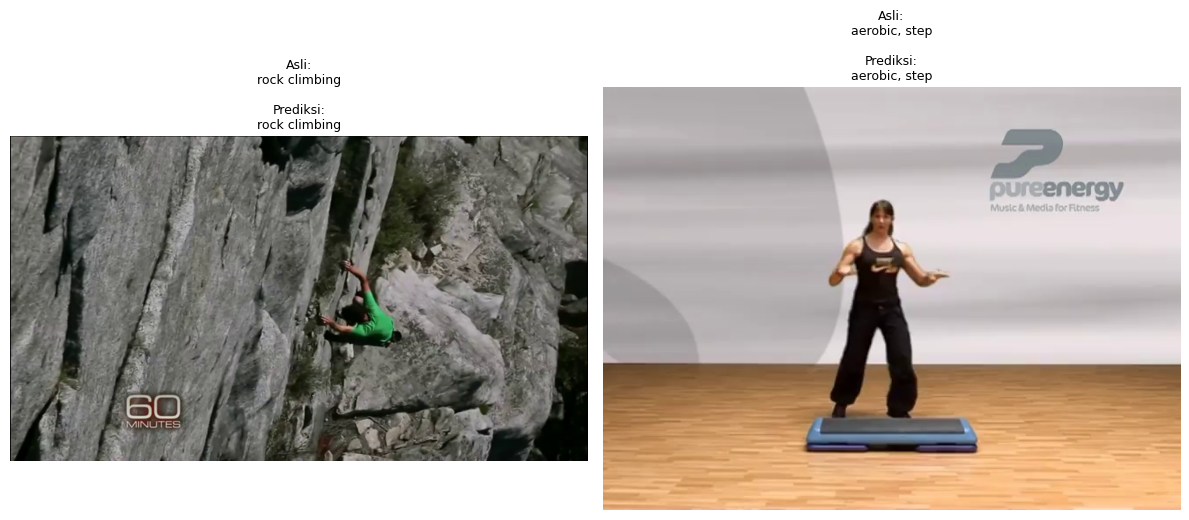

In [25]:
plt.figure(figsize=(12, 5))
for i, (img_rgb, true_label, pred_label) in enumerate(benar):
    plt.subplot(1, 2, i+1)
    plt.imshow(img_rgb)
    plt.title(f"Asli:\n{true_label}\n\nPrediksi:\n{pred_label}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

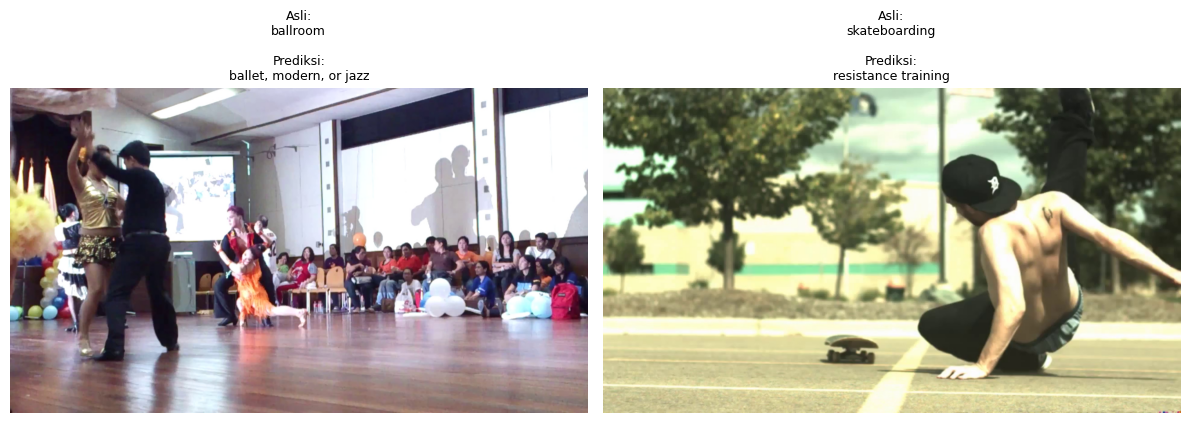

In [31]:
plt.figure(figsize=(12, 5))
for i, (img_rgb, true_label, pred_label) in enumerate(salah):
    plt.subplot(1, 2, i+1)
    plt.imshow(img_rgb)
    plt.title(f"Asli:\n{true_label}\n\nPrediksi:\n{pred_label}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

Jumlah kelas : 20


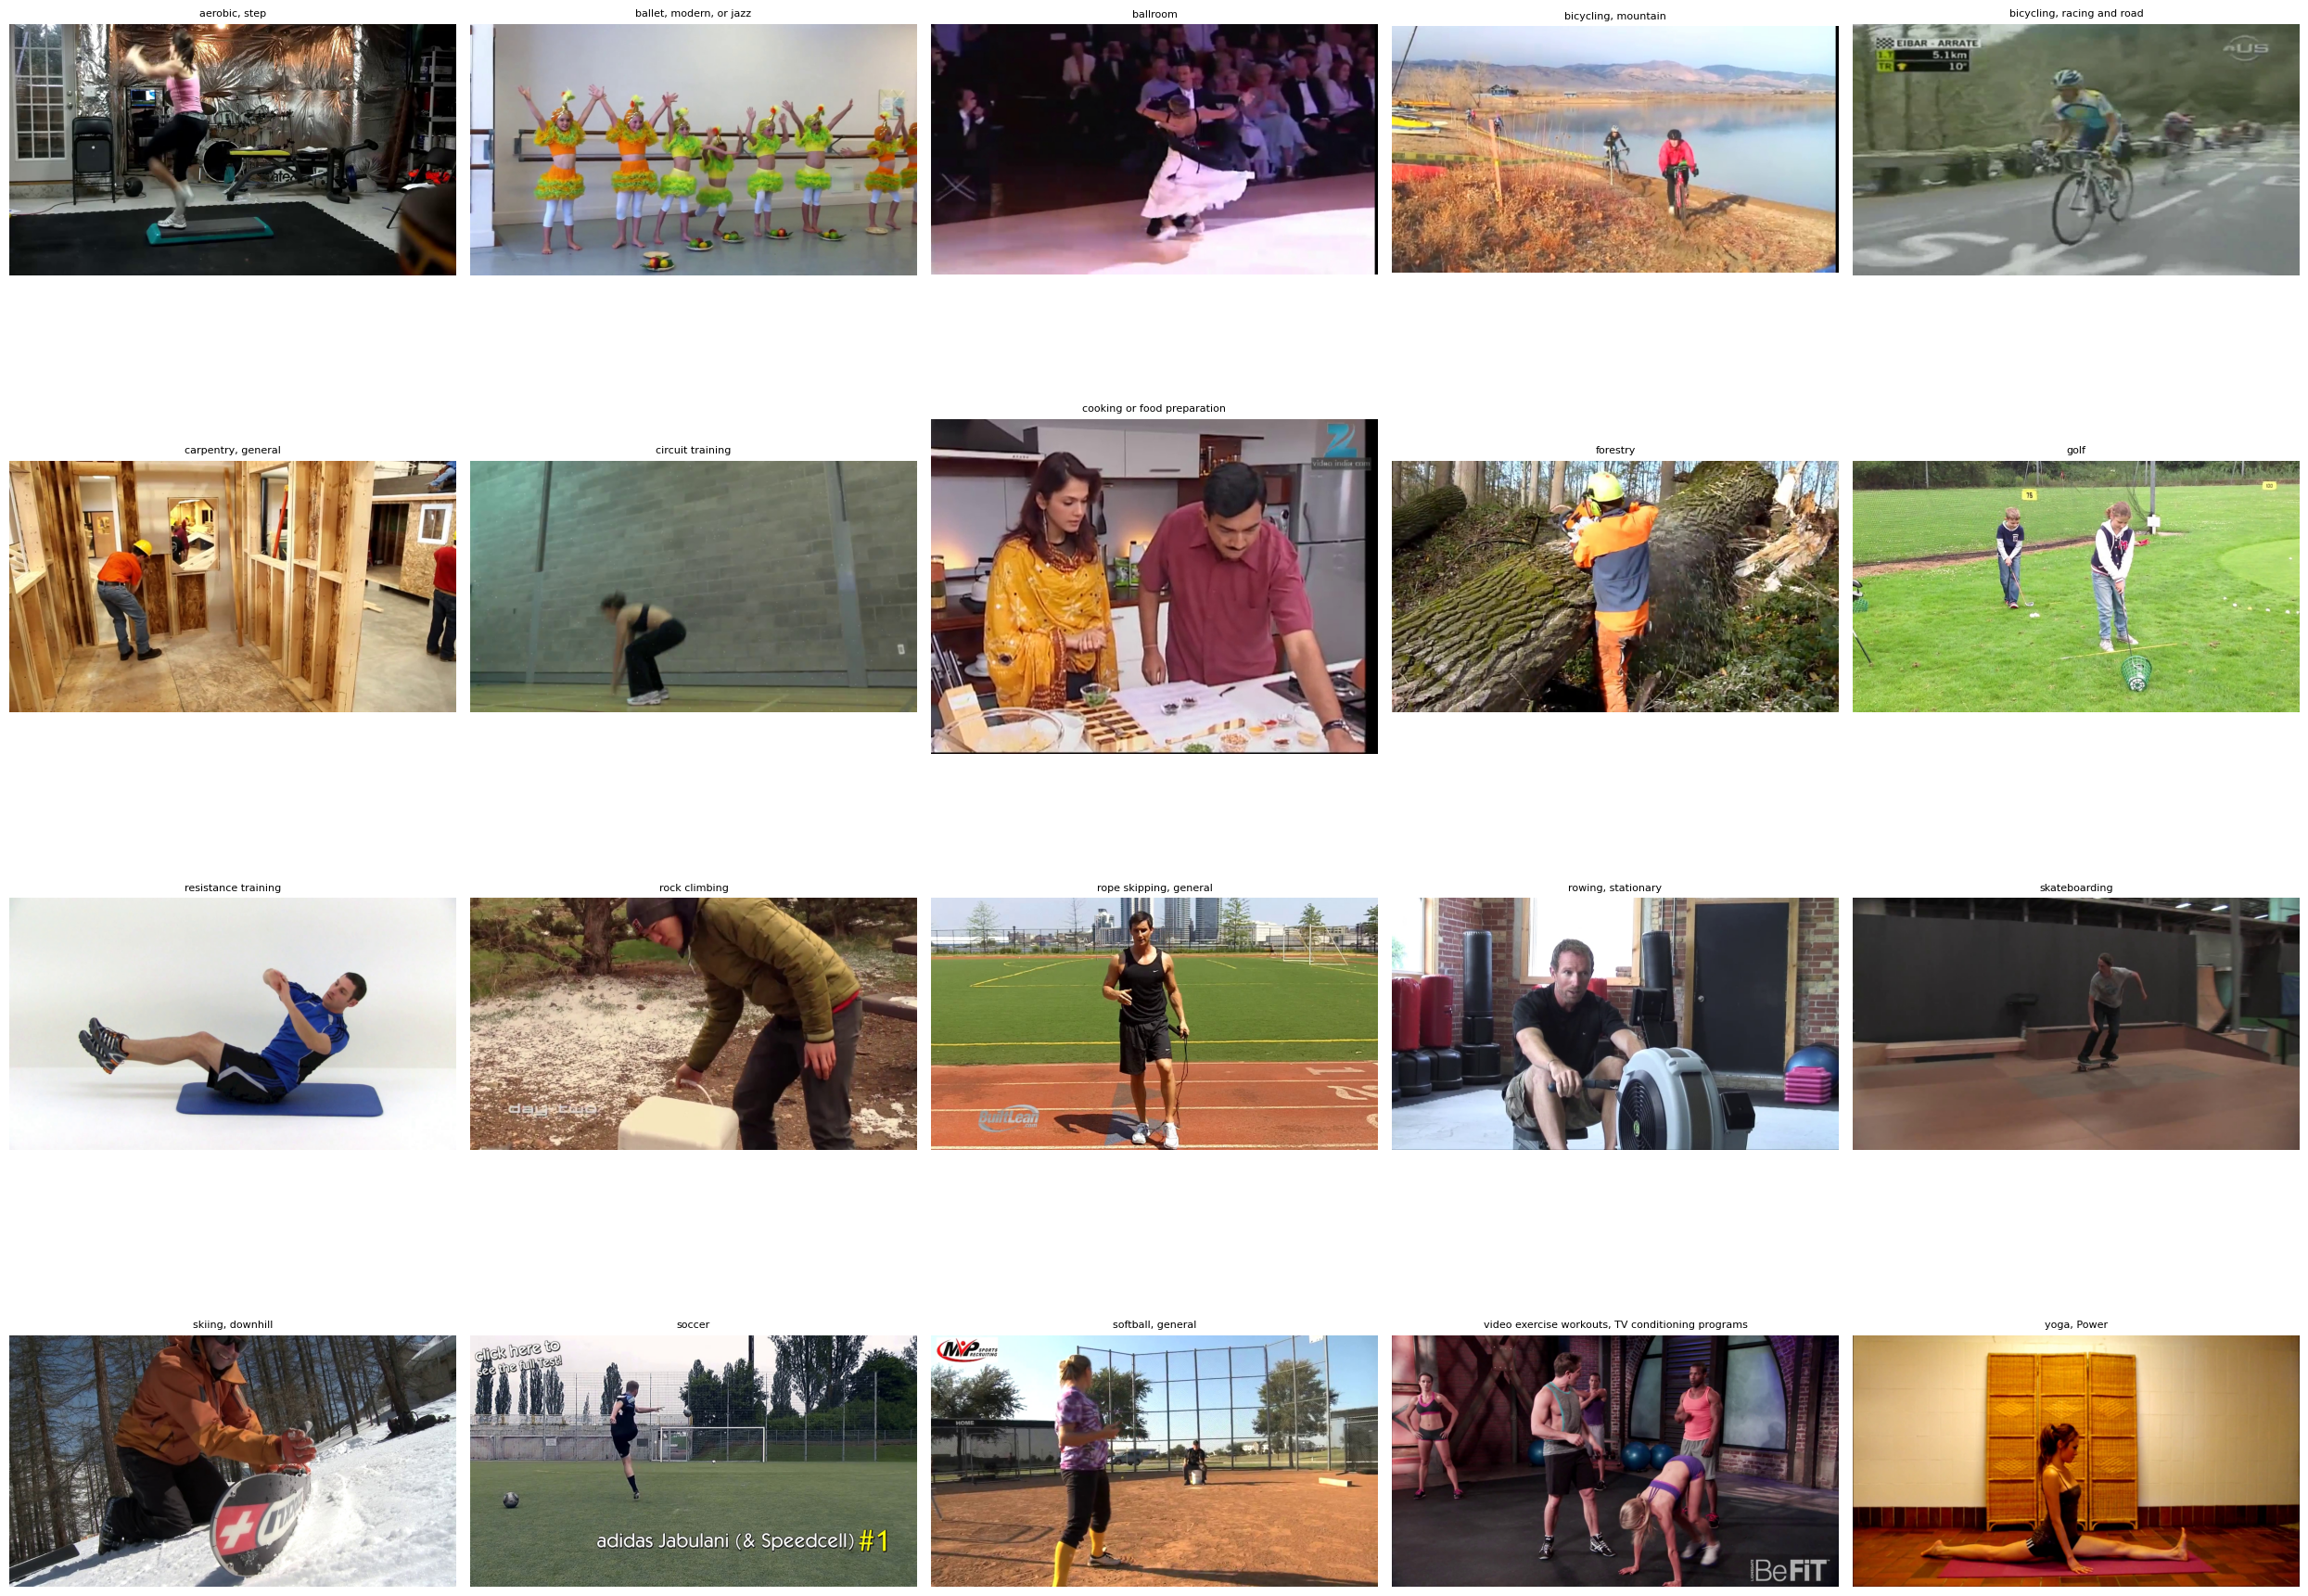

In [22]:
# ==========================================
# TAMPILKAN 20 KELAS DATASET
# (TANPA PREDIKSI MODEL)
# ==========================================

import matplotlib.pyplot as plt
import cv2

# ambil 1 sampel dari setiap kelas
sample_per_class = test_df.groupby("label").first().reset_index()

print("Jumlah kelas :", len(sample_per_class))

plt.figure(figsize=(25,20))

for i, row in enumerate(sample_per_class.itertuples()):

    img = cv2.imread(row.filepath)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(4,5,i+1)
    plt.imshow(img)
    plt.title(row.label, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [1]:
import tensorflow as tf
import numpy as np
import cv2

print(tf.__version__)
print(np.__version__)
print(cv2.__version__)
print(tf.config.list_physical_devices('GPU'))

2.10.0
1.23.5
4.7.0
[]


In [3]:
# ==========================================
# CELL 1
# IMPORT LIBRARY + CEK SYSTEM
# ==========================================

import os
import numpy as np
import pandas as pd
import scipy.io
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import CSVLogger, ModelCheckpoint

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("OpenCV     :", cv2.__version__)
print("GPU        :", tf.config.list_physical_devices('GPU'))

# path project
BASE_DIR = r"C:\Users\TUF\CodeJurnal"

# path dataset image
IMG_DIR = r"D:\Semester 6\METOPEN\Dataset\images"

# path .mat
MAT_PATH = r"D:\Semester 6\METOPEN\Dataset\mpii_human_pose_v1_u12_2\mpii_human_pose_v1_u12_1.mat"

print("\nSemua path siap.")

TensorFlow : 2.10.0
NumPy      : 1.23.5
OpenCV     : 4.7.0
GPU        : []

Semua path siap.


In [4]:
# ==========================================
# CELL 2 (BALANCED DATASET)
# LOAD .MAT + TOP 20 + UNDER SAMPLING
# ==========================================

data = scipy.io.loadmat(MAT_PATH)
release = data["RELEASE"]

annolist = release["annolist"][0,0]
act = release["act"][0,0]

annolist_real = annolist[0]

rows = []

for i in range(len(act)):
    try:
        action = act[i]["act_name"][0]

        if len(action) == 0:
            continue

        label = str(action[0]).strip()

        img_struct = annolist_real[i]["image"][0,0]
        filename = img_struct["name"][0]

        filepath = os.path.join(IMG_DIR, filename)

        if os.path.exists(filepath):
            rows.append([filename, filepath, label])

    except:
        continue

# dataframe awal
df = pd.DataFrame(rows, columns=["filename", "filepath", "label"])

print("Total data valid :", len(df))
print("Jumlah label unik :", df["label"].nunique())

# ambil TOP 20 label terbanyak
top20 = df["label"].value_counts().head(20).index.tolist()

df = df[df["label"].isin(top20)].copy()

# ==========================================
# UNDER SAMPLING -> 140 DATA PER KELAS
# ==========================================

df = (
    df.groupby("label", group_keys=False)
      .apply(lambda x: x.sample(n=140, random_state=42))
      .reset_index(drop=True)
)

# simpan csv baru
csv_path = os.path.join(BASE_DIR, "mpii_labels_top20_balanced.csv")
df.to_csv(csv_path, index=False)

print("\nJumlah data tiap kelas setelah balancing:")
print(df["label"].value_counts())

print("\nCSV disimpan:", csv_path)
print("Total data akhir:", len(df))

Total data valid : 18030
Jumlah label unik : 397

Jumlah data tiap kelas setelah balancing:
label
aerobic, step                                        140
ballet, modern, or jazz                              140
video exercise workouts, TV conditioning programs    140
softball, general                                    140
soccer                                               140
skiing, downhill                                     140
skateboarding                                        140
rowing, stationary                                   140
rope skipping, general                               140
rock climbing                                        140
resistance training                                  140
golf                                                 140
forestry                                             140
cooking or food preparation                          140
circuit training                                     140
carpentry, general                             

C:\Users\TUF\AppData\Local\Temp\ipykernel_12000\2412655482.py:53: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=140, random_state=42))


In [5]:
# ==========================================
# CELL 3
# SPLIT TRAIN / VALIDATION / TEST
# ==========================================

from sklearn.model_selection import train_test_split

# split pertama -> train 70%, sisa 30%
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# split kedua -> dari sisa 30%
# agar jadi val 20% dan test 10%
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.3333,   # 1/3 dari 30% = 10%
    stratify=temp_df["label"],
    random_state=42
)

print("TRAIN DATA :", len(train_df))
print("VAL DATA   :", len(val_df))
print("TEST DATA  :", len(test_df))

print("\nJumlah kelas train :", train_df["label"].nunique())
print("Jumlah kelas val   :", val_df["label"].nunique())
print("Jumlah kelas test  :", test_df["label"].nunique())

# simpan csv split
train_df.to_csv(os.path.join(BASE_DIR, "train_data.csv"), index=False)
val_df.to_csv(os.path.join(BASE_DIR, "val_data.csv"), index=False)
test_df.to_csv(os.path.join(BASE_DIR, "test_data.csv"), index=False)

print("\nCSV split berhasil disimpan.")

TRAIN DATA : 1960
VAL DATA   : 560
TEST DATA  : 280

Jumlah kelas train : 20
Jumlah kelas val   : 20
Jumlah kelas test  : 20

CSV split berhasil disimpan.


In [6]:
# ==========================================
# CELL 4
# IMAGE DATA GENERATOR
# ==========================================

BATCH_SIZE = 8
IMG_SIZE = (224, 224)

train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.inception_v3.preprocess_input,
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.inception_v3.preprocess_input
)

# train generator
train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

# ambil urutan class agar sama semua
classes_list = list(train_gen.class_indices.keys())

# validation generator
val_gen = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
    classes=classes_list
)

# test generator
test_gen = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False,
    classes=classes_list
)

NUM_CLASSES = len(classes_list)

print("Jumlah kelas :", NUM_CLASSES)
print("Nama kelas:")
print(classes_list)

Found 1960 validated image filenames belonging to 20 classes.
Found 560 validated image filenames belonging to 20 classes.
Found 280 validated image filenames belonging to 20 classes.
Jumlah kelas : 20
Nama kelas:
['aerobic, step', 'ballet, modern, or jazz', 'ballroom', 'bicycling, mountain', 'bicycling, racing and road', 'carpentry, general', 'circuit training', 'cooking or food preparation', 'forestry', 'golf', 'resistance training', 'rock climbing', 'rope skipping, general', 'rowing, stationary', 'skateboarding', 'skiing, downhill', 'soccer', 'softball, general', 'video exercise workouts, TV conditioning programs', 'yoga, Power']


In [7]:
# ==========================================
# CELL 5
# BUILD MODEL INCEPTIONV3 FINAL
# ==========================================

base_model = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

# freeze sebagian layer awal
for layer in base_model.layers[:-60]:
    layer.trainable = False

for layer in base_model.layers[-60:]:
    layer.trainable = True

# top layer
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
x = Dense(256, activation="relu")(x)
x = BatchNormalization()(x)
output = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 111, 111, 32  864         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 111, 111, 32  96         ['conv2d[0][0]']                 
 alization)                     )                                                             

In [8]:
# ==========================================
# CELL 6
# TRAINING BALANCED
# ==========================================

from tensorflow.keras.callbacks import CSVLogger, ModelCheckpoint

csv_logger = CSVLogger(
    os.path.join(BASE_DIR, "history_balanced.csv"),
    append=False
)

checkpoint = ModelCheckpoint(
    os.path.join(BASE_DIR, "best_model_balanced.h5"),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

EPOCHS = 100

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=[csv_logger, checkpoint],
    verbose=1
)

model.save(os.path.join(BASE_DIR, "final_model_balanced.h5"))

print("Training selesai.")

Epoch 1/100
245/245 [==============================] - ETA: 0s - loss: 1.8819 - accuracy: 0.4612
Epoch 1: val_accuracy improved from -inf to 0.72500, saving model to C:\Users\TUF\CodeJurnal\best_model_balanced.h5
245/245 [==============================] - 170s 658ms/step - loss: 1.8819 - accuracy: 0.4612 - val_loss: 0.9191 - val_accuracy: 0.7250
Epoch 2/100
245/245 [==============================] - ETA: 0s - loss: 0.9209 - accuracy: 0.7286
Epoch 2: val_accuracy improved from 0.72500 to 0.79464, saving model to C:\Users\TUF\CodeJurnal\best_model_balanced.h5
245/245 [==============================] - 126s 512ms/step - loss: 0.9209 - accuracy: 0.7286 - val_loss: 0.7086 - val_accuracy: 0.7946
Epoch 3/100
245/245 [==============================] - ETA: 0s - loss: 0.6342 - accuracy: 0.8092
Epoch 3: val_accuracy improved from 0.79464 to 0.81786, saving model to C:\Users\TUF\CodeJurnal\best_model_balanced.h5
245/245 [==============================] - 125s 509ms/step - loss: 0.6342 - accuracy:

In [9]:
# ==========================================
# CELL 7
# TEST ACCURACY
# ==========================================

loss, acc = model.evaluate(test_gen, verbose=1)

print("\nTEST LOSS     :", loss)
print("TEST ACCURACY :", acc)

35/35 [==============================] - 7s 186ms/step - loss: 0.5587 - accuracy: 0.8893

TEST LOSS     : 0.5586504340171814
TEST ACCURACY : 0.8892857432365417


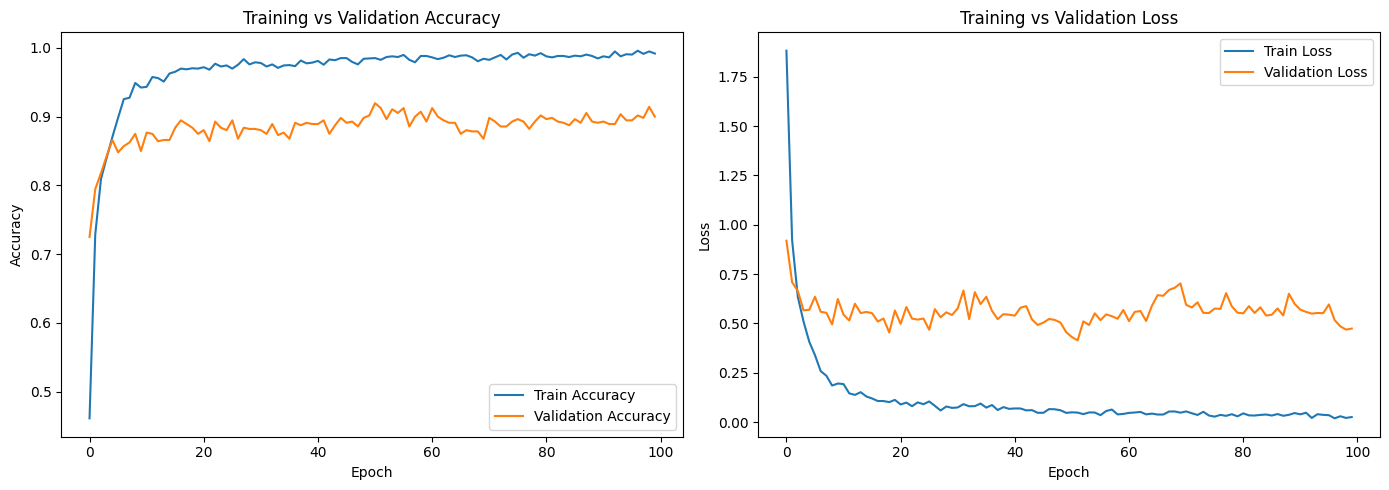

In [10]:
# ==========================================
# CELL 8
# GRAFIK BALANCED
# ==========================================

history_df = pd.read_csv("history_balanced.csv")

plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history_df["accuracy"], label="Train Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history_df["loss"], label="Train Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
# ==========================================
# CELL 9
# CLASSIFICATION REPORT
# ==========================================

import numpy as np
from sklearn.metrics import classification_report

pred = model.predict(test_gen)

y_pred = np.argmax(pred, axis=1)
y_true = test_gen.classes

class_names = list(test_gen.class_indices.keys())

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

35/35 [==============================] - 6s 139ms/step
                                                   precision    recall  f1-score   support

                                    aerobic, step     1.0000    1.0000    1.0000        14
                          ballet, modern, or jazz     1.0000    0.6429    0.7826        14
                                         ballroom     0.8571    0.8571    0.8571        14
                              bicycling, mountain     0.8667    0.9286    0.8966        14
                       bicycling, racing and road     0.8667    0.9286    0.8966        14
                               carpentry, general     0.9286    0.9286    0.9286        14
                                 circuit training     0.9286    0.9286    0.9286        14
                      cooking or food preparation     0.8667    0.9286    0.8966        14
                                         forestry     1.0000    0.9286    0.9630        14
                                  

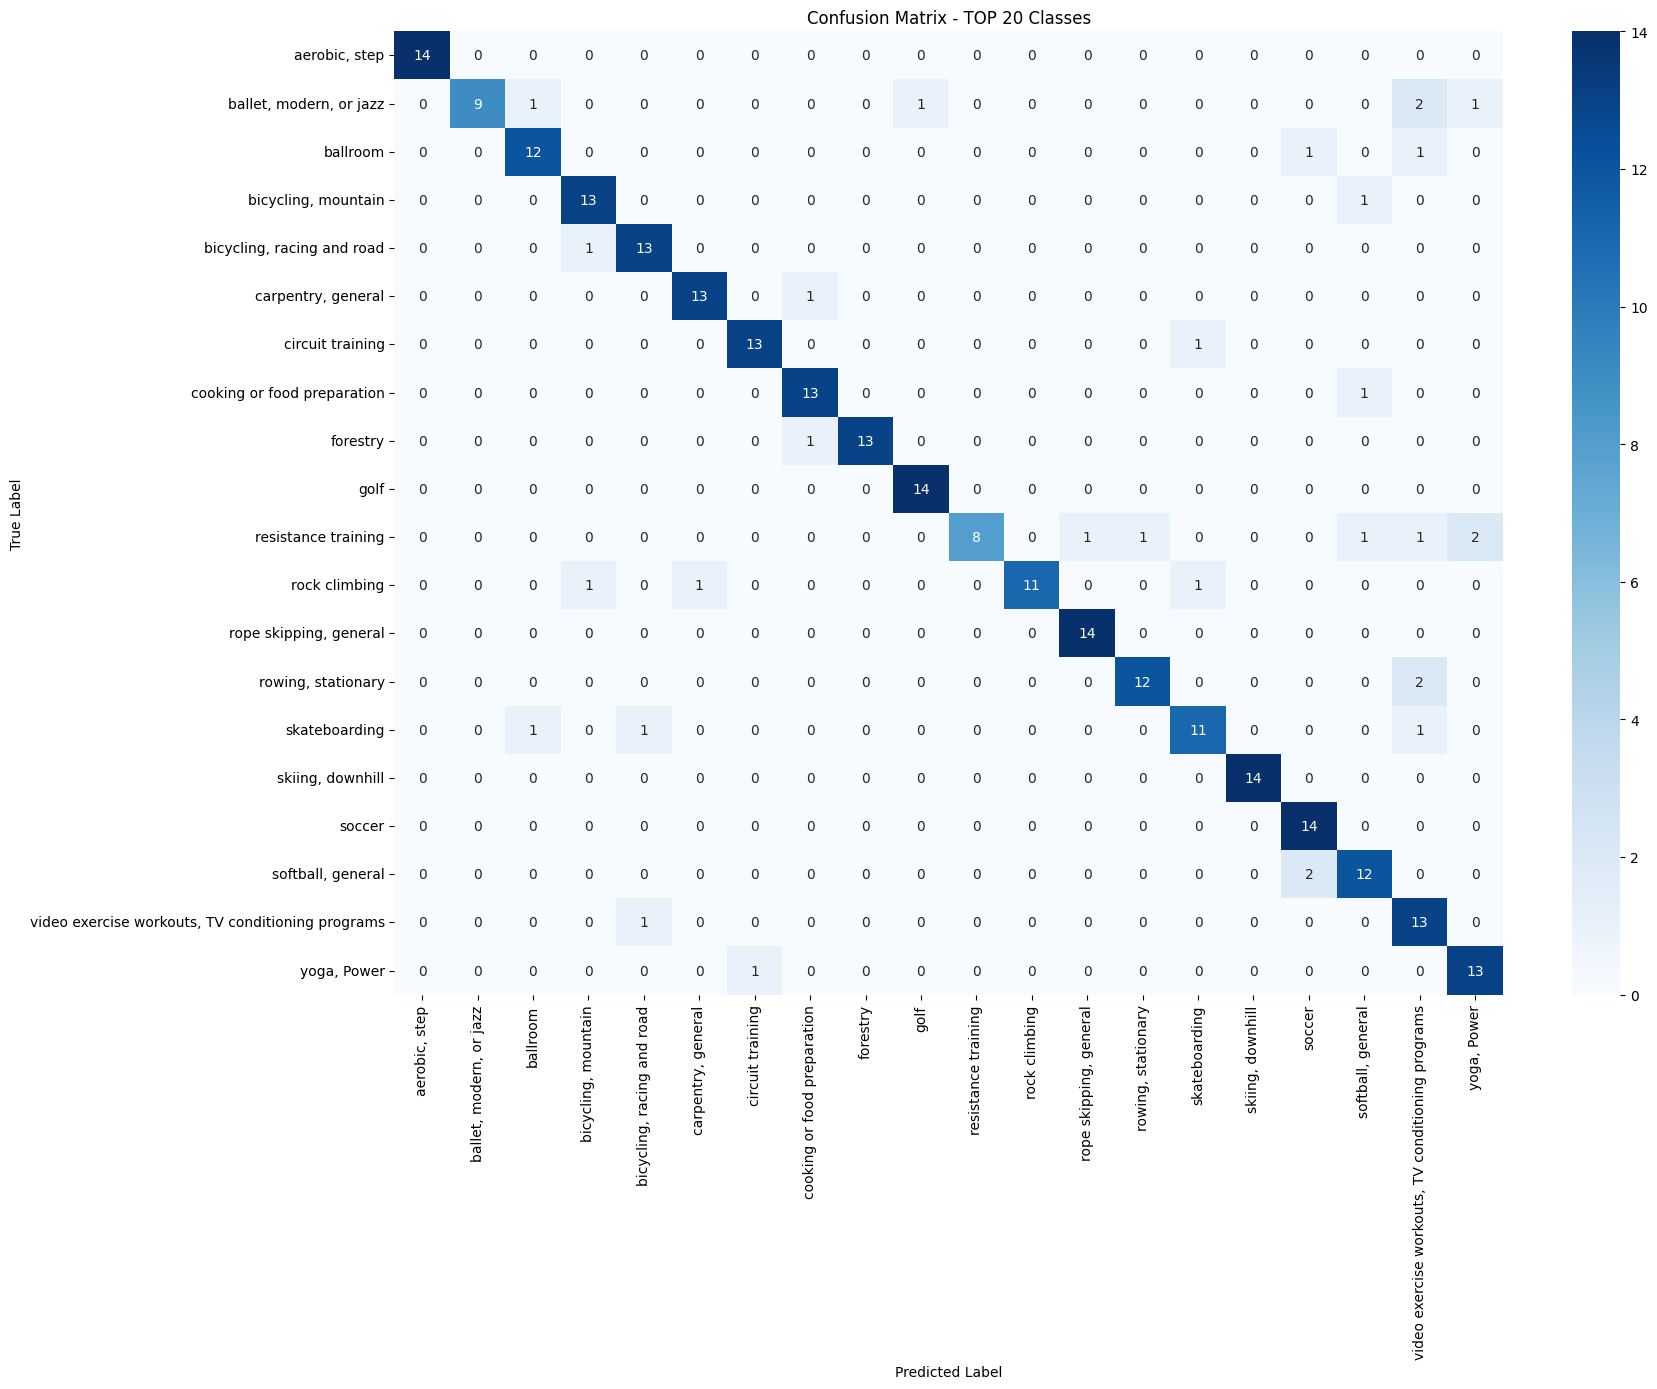

In [12]:
# ==========================================
# CELL 10
# CONFUSION MATRIX
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18,14))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - TOP 20 Classes")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()